<a href="https://colab.research.google.com/github/yeaye-hufs/DM_Cancer-vs-Normal-Classification-ML-Model/blob/main/DM_Project_4_XGBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (81, 398)

===== Class Distribution =====
Cancer (1): 72
Normal (0): 9

scale_pos_weight = 1.000

===== Dataset Split =====
Train: (60, 397)
Test : (21, 397)

===== 5-Fold Cross Validation =====
Fold AUCs:
[1. 1. 1. 1. 1.]

Mean AUC = 1.0000
Std AUC  = 0.0000

===== Test Set Performance =====
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00         2
      Cancer       1.00      1.00      1.00        19

    accuracy                           1.00        21
   macro avg       1.00      1.00      1.00        21
weighted avg       1.00      1.00      1.00        21


Test ROC-AUC = 1.0000


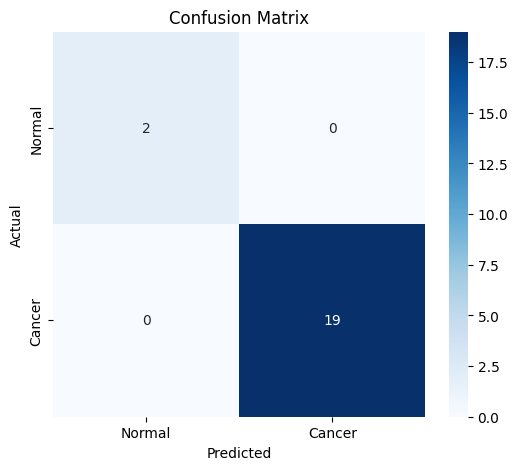

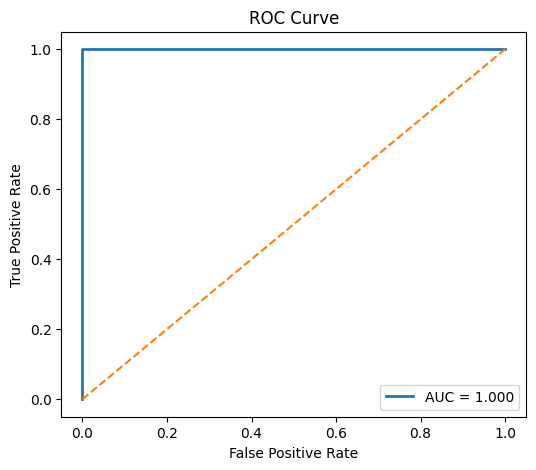


===== Top 15 Important Genes =====
ENSG00000143167    0.177227
ENSG00000116771    0.172321
ENSG00000105219    0.164848
ENSG00000060718    0.106206
ENSG00000143320    0.078662
ENSG00000000460    0.063394
ENSG00000008300    0.059512
ENSG00000092051    0.031704
ENSG00000011426    0.031470
ENSG00000075702    0.020890
ENSG00000173227    0.019977
ENSG00000146242    0.011977
ENSG00000088340    0.010339
ENSG00000120645    0.009696
ENSG00000149948    0.009534
dtype: float32


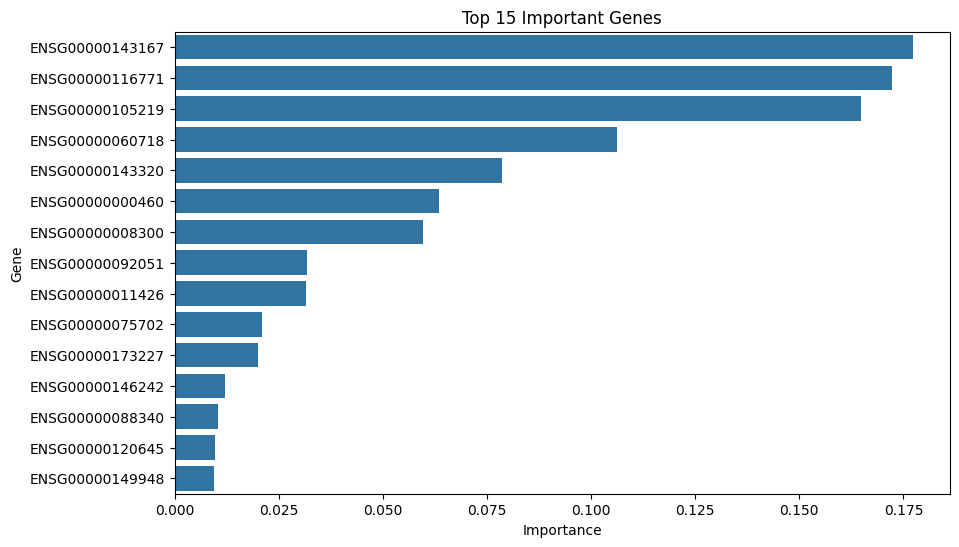


Top15_Important_Genes.csv 저장 완료


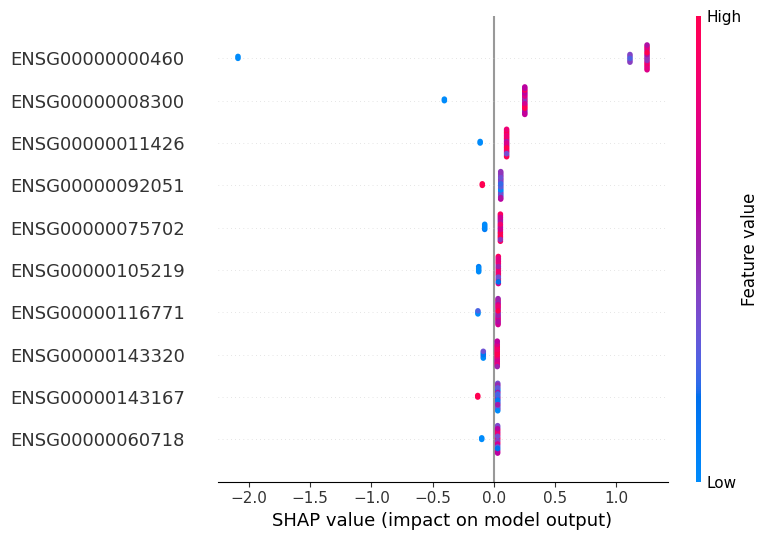

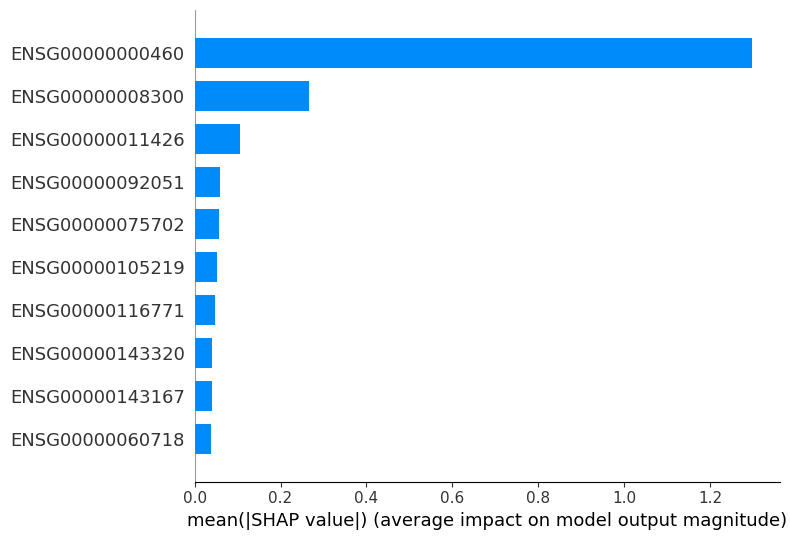

                Gene  Mean_SHAP
0    ENSG00000000460   1.297475
2    ENSG00000008300   0.266872
4    ENSG00000011426   0.104793
57   ENSG00000092051   0.059596
38   ENSG00000075702   0.057345
93   ENSG00000105219   0.053077
126  ENSG00000116771   0.047866
224  ENSG00000143320   0.041529
222  ENSG00000143167   0.040974
22   ENSG00000060718   0.037111
351  ENSG00000173227   0.027923
235  ENSG00000146242   0.025186
51   ENSG00000088340   0.023622
137  ENSG00000120645   0.022910
248  ENSG00000149948   0.022571
24   ENSG00000064989   0.021943
308  ENSG00000166736   0.021365
15   ENSG00000046774   0.020434
349  ENSG00000172461   0.020431
266  ENSG00000158089   0.000000


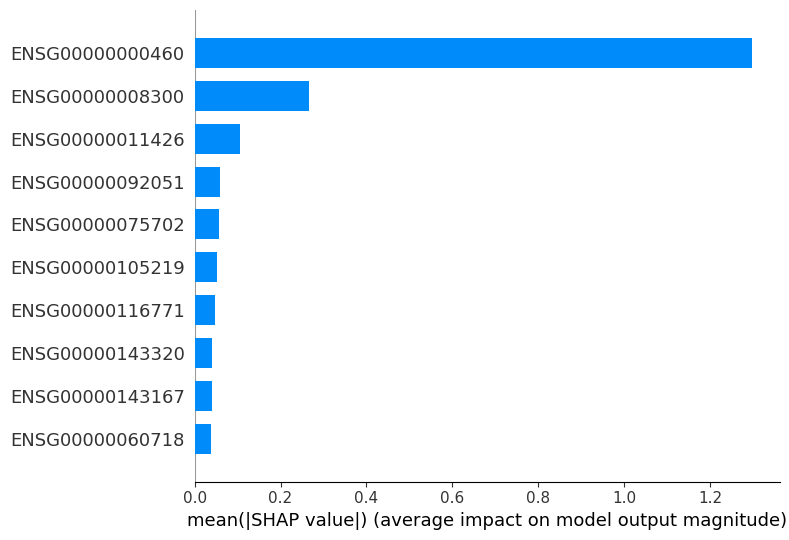

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

from xgboost import XGBClassifier

# =====================================================
# 1. 데이터 로드
# =====================================================

df = pd.read_csv(
    "TCGA_Lung_Cancer_ML_Ready.csv",
    index_col=0
)

print("Dataset Shape:", df.shape)

# =====================================================
# 2. Feature / Label 분리
# =====================================================

X = df.drop(columns=["Target"])
y = df["Target"]

# 문자열 라벨 처리
if y.dtype == "object":
    y = y.map({
        "Cancer": 0,
        "Normal": 1
    })

# =====================================================
# 3. 클래스 분포 확인
# =====================================================

num_normal = np.sum(y == 0)
num_cancer = np.sum(y == 1)

print("\n===== Class Distribution =====")
print(f"Cancer (1): {num_cancer}")
print(f"Normal (0): {num_normal}")

# XGBoost 권장 방식
scale_pos_weight_val = 1

print(f"\nscale_pos_weight = {scale_pos_weight_val:.3f}")

# =====================================================
# 4. Train / Test Split
# =====================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print("\n===== Dataset Split =====")
print("Train:", X_train.shape)
print("Test :", X_test.shape)

# 저장
train_df = pd.concat([X_train, y_train], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)

train_df.to_csv("TCGA_Lung_Cancer_Train.csv")
test_df.to_csv("TCGA_Lung_Cancer_Test.csv")

# =====================================================
# 5. XGBoost 모델
# =====================================================

model = XGBClassifier(
    objective='binary:logistic',

    n_estimators=1000,
    learning_rate=0.05,

    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,

    scale_pos_weight=scale_pos_weight_val,

    eval_metric='auc',

    random_state=42
)

# =====================================================
# 6. 학습
# =====================================================

model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_test, y_test)
    ],
    verbose=False
)

# =====================================================
# 7. 5-Fold Cross Validation
# =====================================================

print("\n===== 5-Fold Cross Validation =====")

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring='roc_auc'
)

print("Fold AUCs:")
print(cv_scores)

print(f"\nMean AUC = {cv_scores.mean():.4f}")
print(f"Std AUC  = {cv_scores.std():.4f}")

# =====================================================
# 8. Test Set Prediction
# =====================================================

y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:,1]

# =====================================================
# 9. 성능 평가
# =====================================================

print("\n===== Test Set Performance =====")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Normal",
            "Cancer"
        ]
    )
)

auc_score = roc_auc_score(
    y_test,
    y_prob
)

print(f"\nTest ROC-AUC = {auc_score:.4f}")

# =====================================================
# 10. Confusion Matrix
# =====================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal','Cancer'],
    yticklabels=['Normal','Cancer']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

# =====================================================
# 11. ROC Curve
# =====================================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    lw=2,
    label=f"AUC = {auc_score:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

# =====================================================
# 12. Feature Importance
# =====================================================

feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
)

feature_importance = feature_importance.sort_values(
    ascending=False
)

top15 = feature_importance.head(15)

print("\n===== Top 15 Important Genes =====")
print(top15)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top15.values,
    y=top15.index
)

plt.title("Top 15 Important Genes")
plt.xlabel("Importance")
plt.ylabel("Gene")

plt.show()

# =====================================================
# 13. 결과 저장
# =====================================================

top15.to_csv(
    "Top15_Important_Genes.csv"
)

print("\nTop15_Important_Genes.csv 저장 완료")

# ====================================================
# 14. SHAP 분석
# ====================================================

!pip install shap

import shap

# XGBoost 모델 설명기 생성
explainer = shap.TreeExplainer(model)

# Test set에 대한 SHAP 값 계산
shap_values = explainer.shap_values(X_test)

# SHAP summary plot
shap.summary_plot(
    shap_values,
    X_test,
    max_display=10
)

# SHAP importance bar plot
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    max_display=10
)

# 유전자 중요도 표 저장
feature_importance = pd.DataFrame({
    'Gene': X_train.columns,
    'Mean_SHAP': np.abs(shap_values).mean(axis=0)
})

feature_importance = feature_importance.sort_values(
    by='Mean_SHAP',
    ascending=False
)

print(feature_importance.head(20))

feature_importance.to_csv(
    "SHAP_Top_Genes.csv",
    index=False
)

# 발표용 figure 저장
plt.figure(figsize=(8,6))

shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    max_display=10,
    show=False
)

plt.tight_layout()

plt.savefig(
    "SHAP_Top10_Genes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()